# Lab 9 - Morphological Operations
**Completed assignment | Python + OpenCV**

**Objective:** Apply erosion, dilation, opening, and closing to a new binary image, then compare structuring element shapes and sizes.

**Input:** `Balls(1).png` (different from the images used in the original lab notebook).

**Note:** Keep `Balls(1).png` in the same folder as this notebook. The image is loaded as a normal file, not embedded as long Base64 code.

Binary image shape: (620, 640)
Otsu threshold: 128.0


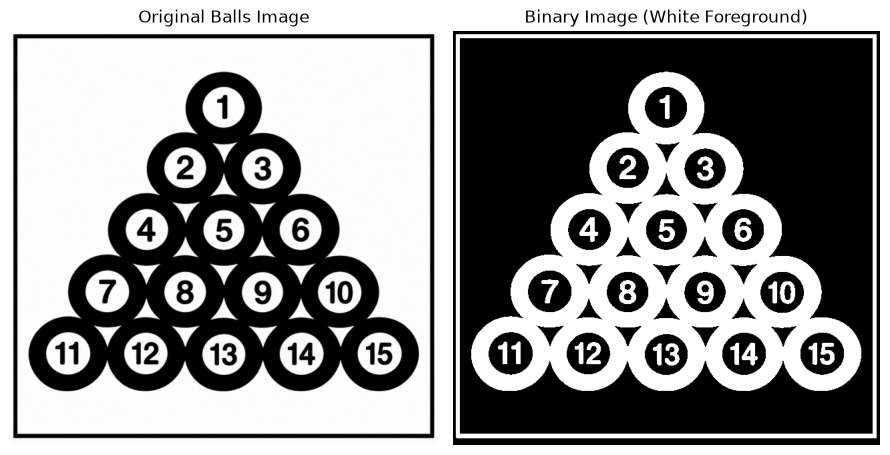

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

image_path = Path('Balls.png')
if not image_path.exists():
    raise FileNotFoundError('Place Balls(1).png in the same folder as the notebook.')
Path('lab9_figures').mkdir(exist_ok=True)

# Resize to make the 3x3, 5x5 and 7x7 differences easier to see.
gray_full = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
new_width = 640
new_height = round(gray_full.shape[0] * new_width / gray_full.shape[1])
gray = cv2.resize(gray_full, (new_width, new_height), interpolation=cv2.INTER_AREA)

# The rings and numbers are dark in the original; make them WHITE foreground.
threshold, binary = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
print('Binary image shape:', binary.shape)
print('Otsu threshold:', threshold)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original Balls Image')
axes[1].imshow(binary, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Binary Image (White Foreground)')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
fig.savefig('lab9_figures/input_binary.png', dpi=130, bbox_inches='tight')
plt.show()

## Task 1 - Apply morphological operations
Apply **erosion**, **dilation**, **opening**, and **closing** on the selected binary image using a **5×5 square** structuring element.

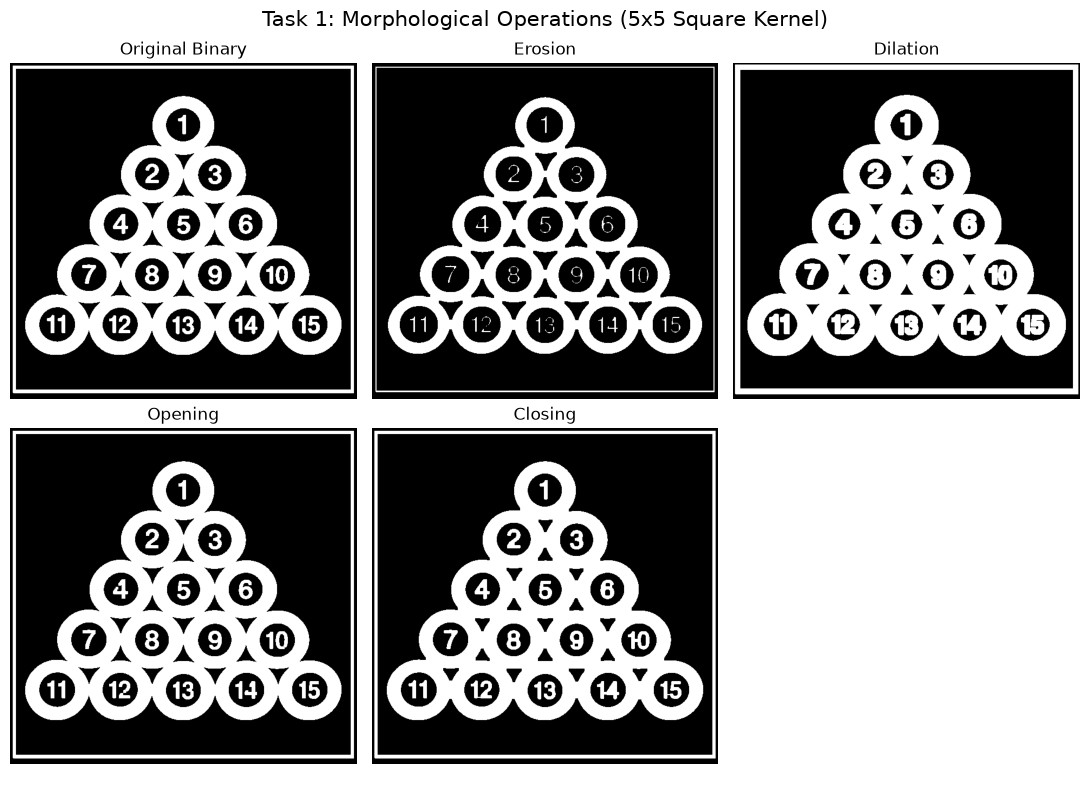

In [2]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

# Four operations demonstrated in the original lab.
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

names = ['Original Binary', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [binary, erosion, dilation, opening, closing]
fig, axes = plt.subplots(2, 3, figsize=(11, 8))
for ax, name, image in zip(axes.flat, names, images):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name, fontsize=12)
    ax.axis('off')
axes.flat[-1].axis('off')
fig.suptitle('Task 1: Morphological Operations (5x5 Square Kernel)', fontsize=15)
fig.tight_layout()
fig.savefig('lab9_figures/task1_operations.png', dpi=140, bbox_inches='tight')
plt.show()

**Task 1 observations:**
- **Erosion** reduces the white foreground and makes the rings/numbers thinner.
- **Dilation** expands the white foreground and makes the rings/numbers thicker.
- **Opening** (erosion followed by dilation) removes small white details and smooths protrusions.
- **Closing** (dilation followed by erosion) fills small black gaps and can join nearby white regions.

These effects depend on the foreground being **white**, which is why binary inversion was used.

## Task 2 - Experiment with structuring elements
Compare **square**, **cross**, and **ellipse** structuring elements at sizes **3×3, 5×5, and 7×7**. Each grid uses the same original binary image so the comparison is fair.

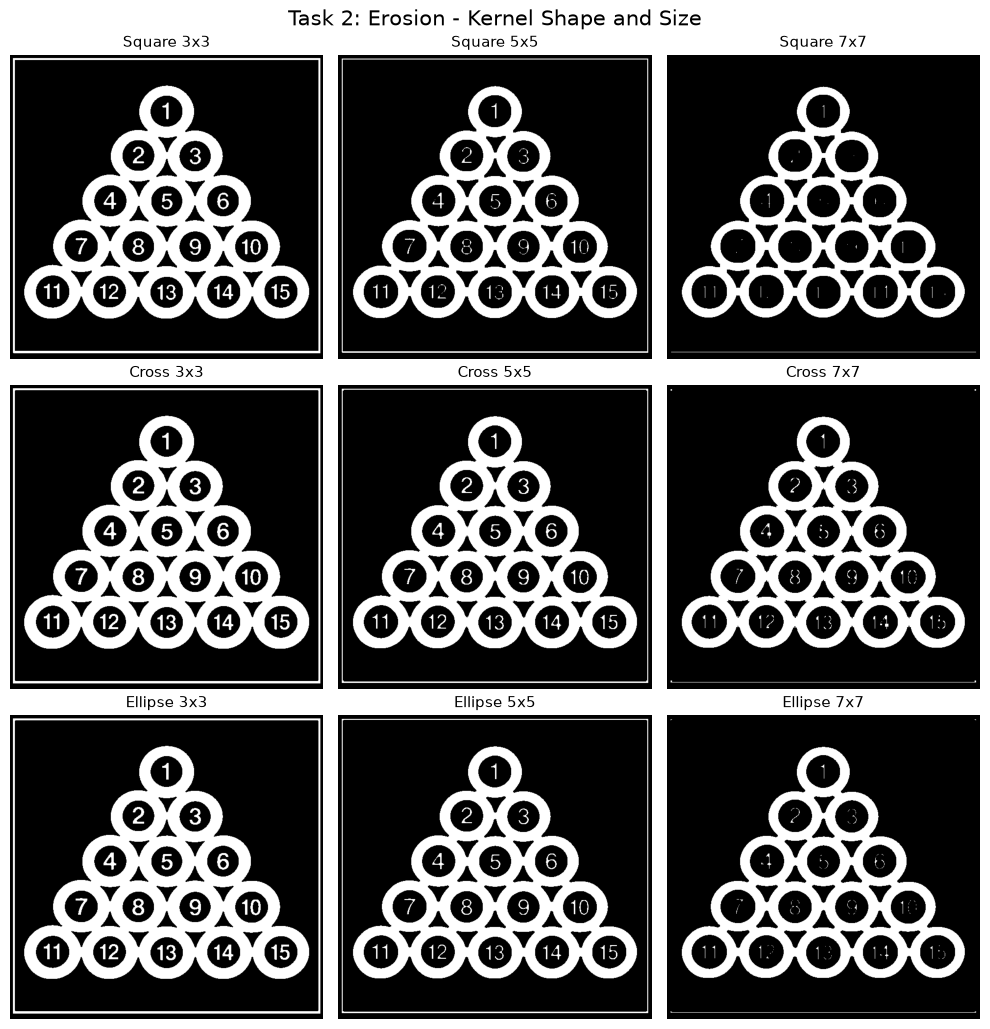

In [3]:
shapes = {
    'Square': cv2.MORPH_RECT,
    'Cross': cv2.MORPH_CROSS,
    'Ellipse': cv2.MORPH_ELLIPSE
}
sizes = [3, 5, 7]

results = []
fig, axes = plt.subplots(3, 3, figsize=(10, 10.5))
for row, (shape_name, shape_code) in enumerate(shapes.items()):
    for col, size in enumerate(sizes):
        k = cv2.getStructuringElement(shape_code, (size, size))
        eroded = cv2.erode(binary, k, iterations=1)
        dilated = cv2.dilate(binary, k, iterations=1)
        results.append({
            'Shape': shape_name,
            'Size': f'{size}x{size}',
            'Erosion white pixels': int(np.count_nonzero(eroded)),
            'Dilation white pixels': int(np.count_nonzero(dilated)),
        })
        axes[row, col].imshow(eroded, cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(f'{shape_name} {size}x{size}', fontsize=11)
        axes[row, col].axis('off')
fig.suptitle('Task 2: Erosion - Kernel Shape and Size', fontsize=15)
fig.tight_layout()
fig.savefig('lab9_figures/task2_erosion.png', dpi=140, bbox_inches='tight')
plt.show()

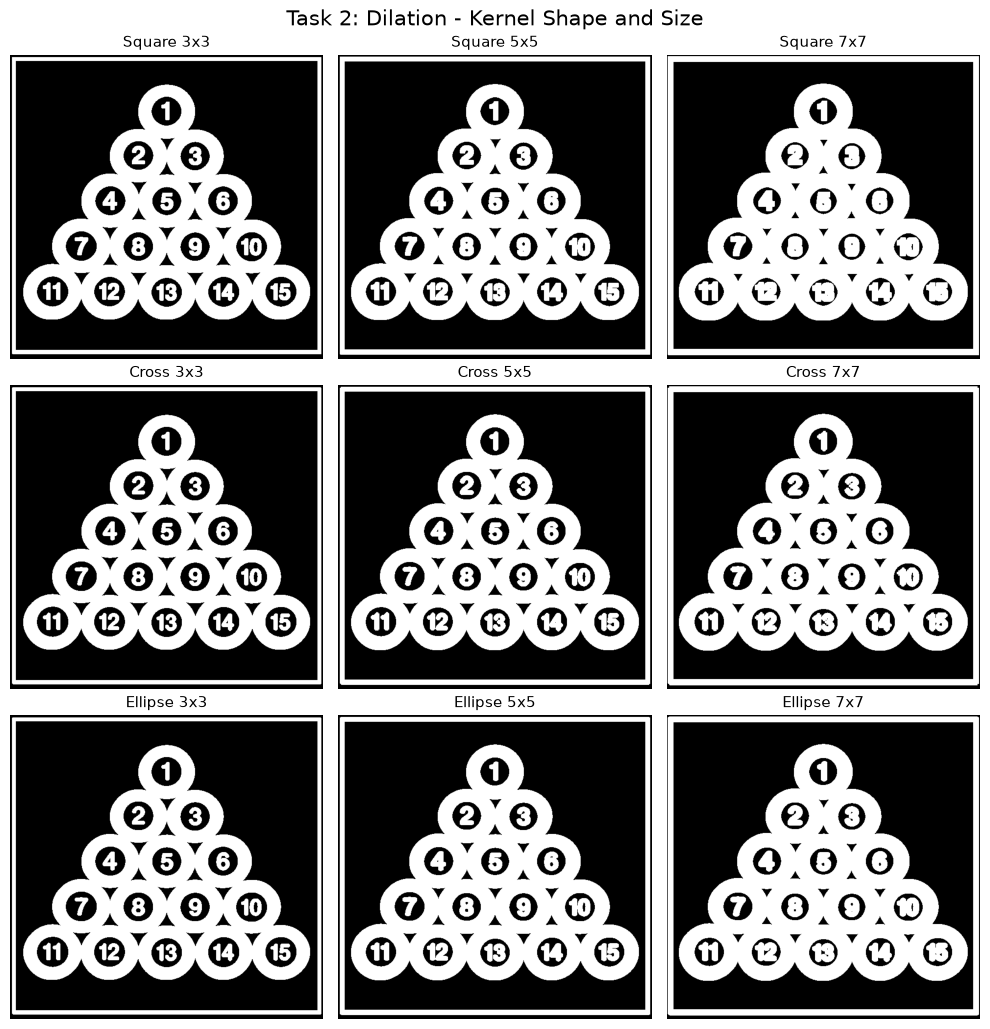

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10.5))
for row, (shape_name, shape_code) in enumerate(shapes.items()):
    for col, size in enumerate(sizes):
        k = cv2.getStructuringElement(shape_code, (size, size))
        dilated = cv2.dilate(binary, k, iterations=1)
        axes[row, col].imshow(dilated, cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(f'{shape_name} {size}x{size}', fontsize=11)
        axes[row, col].axis('off')
fig.suptitle('Task 2: Dilation - Kernel Shape and Size', fontsize=15)
fig.tight_layout()
fig.savefig('lab9_figures/task2_dilation.png', dpi=140, bbox_inches='tight')
plt.show()

### Numerical comparison
The number of white pixels offers a simple way to compare how much the foreground has shrunk (erosion) or expanded (dilation).

In [5]:
results_df = pd.DataFrame(results)
print('Original white pixels:', int(np.count_nonzero(binary)))
print(results_df.to_string(index=False))

Original white pixels: 126873
  Shape Size  Erosion white pixels  Dilation white pixels
 Square  3x3                109866                 143632
 Square  5x5                 92752                 159721
 Square  7x7                 76456                 174981
  Cross  3x3                113254                 140417
  Cross  5x5                 99732                 153589
  Cross  7x7                 86400                 166212
Ellipse  3x3                113254                 140417
Ellipse  5x5                 97068                 155951
Ellipse  7x7                 83339                 168666


### Task 2 comparison and conclusion
- **Kernel size:** Increasing the kernel from **3×3** to **7×7** causes **stronger erosion** (fewer white pixels) and **stronger dilation** (more white pixels).
- **Kernel shape:** A **square** includes the diagonal neighbors and generally causes the largest change. A **cross** changes the image less because it uses only horizontal and vertical directions. An **ellipse** usually gives an intermediate, more rounded effect.
- **Small kernel detail:** In OpenCV, the **3×3 cross and 3×3 ellipse** are the same pattern, so their outputs match.

**Conclusion:** Morphological operations change object size and small details. Kernel **shape and size** directly control how strongly erosion or dilation affects the image.

**Reference:** [OpenCV - Morphological Transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)